 DFS/BFS/UCS/A*
------------------------------------------------------------


Number of nodes (min 30):  60
all edge weights be the same? (y/n):  n
Start node (default 1):  5
Goal node (default 60):  42



Results:
------------------------------------------------------------
DFS:
  Path: [5, 1, 2, 3, 11, 4, 6, 9, 14, 12, 42]
  Expanded nodes: 59
  Path length (edges): 10
  Path cost: 4896

BFS:
  Path: [5, 12, 42]
  Expanded nodes: 24
  Path length (edges): 2
  Path cost: 652

UCS:
  Path: [5, 12, 42]
  Expanded nodes: 16
  Path length (edges): 2
  Path cost: 652

A*:
  Path: [5, 12, 42]
  Expanded nodes: 6
  Path length (edges): 2
  Path cost: 652



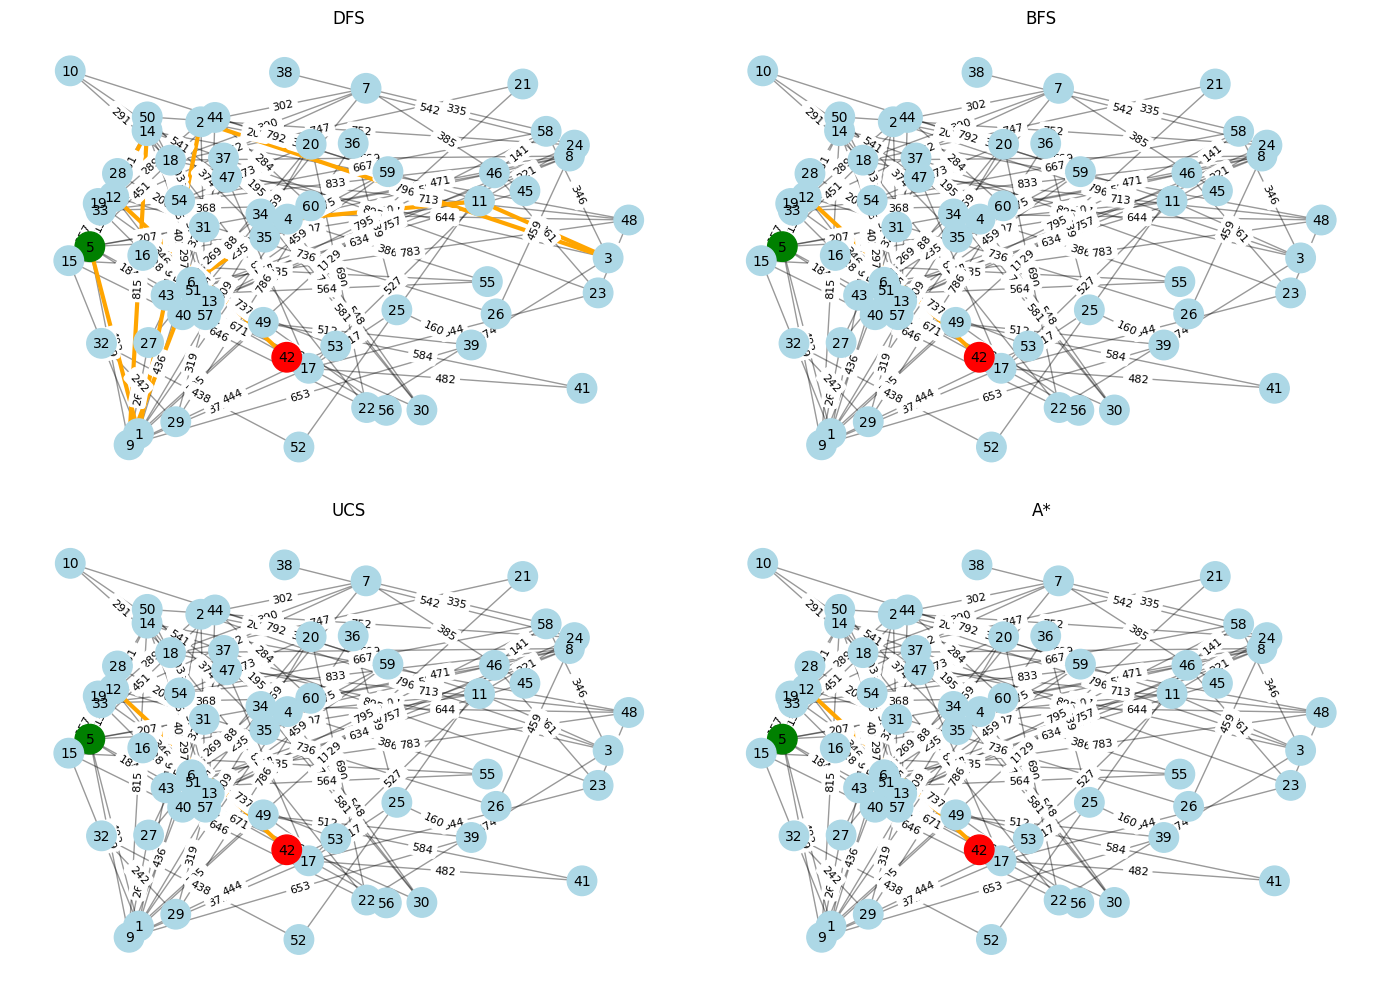

In [1]:
import random
import math
from collections import deque
import heapq

import networkx as nx
import matplotlib.pyplot as plt


def make_random_connected_graph(n, extra_edges, same_weight=True, fixed_weight=1, seed=None):
    if n < 30:
        raise ValueError("Error: number of nodes must be at least 30.")

    pos = {i: (random.random(), random.random()) for i in range(1, n + 1)}

    edges = set()

    for node in range(2, n + 1):
        parent = random.randint(1, node - 1)
        u, v = sorted((node, parent))
        edges.add((u, v))

    target_edges = (n - 1) + extra_edges
    while len(edges) < target_edges:
        u = random.randint(1, n)
        v = random.randint(1, n)
        if u == v:
            continue
        a, b = sorted((u, v))
        edges.add((a, b))

    SCALE = 1000

    weights = {}
    for (u, v) in edges:
        if same_weight:
            w = fixed_weight
        else:
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            dist = math.hypot(x1 - x2, y1 - y2)
            w = int(dist * SCALE) + 1
        weights[(u, v)] = w

    adj = {i: [] for i in range(1, n + 1)}
    for (u, v), w in weights.items():
        adj[u].append((v, w))
        adj[v].append((u, w))

    return adj, weights, pos, edges


def path_cost(path, weights):
    if not path or len(path) == 1:
        return 0
    total = 0
    for i in range(len(path) - 1):
        u, v = sorted((path[i], path[i + 1]))
        total += weights[(u, v)]
    return total


def dfs(adj, start, goal):
    stack = [(start, [start])]
    visited = set()
    expanded = 0

    while stack:
        node, path = stack.pop()

        if node in visited:
            continue

        visited.add(node)
        expanded += 1

        if node == goal:
            return path, expanded

        neighbors = sorted(adj[node], key=lambda x: x[0], reverse=True)
        for nxt, _w in neighbors:
            if nxt not in visited:
                stack.append((nxt, path + [nxt]))

    return None, expanded


def bfs(adj, start, goal):
    q = deque([start])
    visited = set([start])
    parent = {start: None}
    expanded = 0

    while q:
        node = q.popleft()
        expanded += 1

        if node == goal:
            break

        for nxt, _w in sorted(adj[node], key=lambda x: x[0]):
            if nxt not in visited:
                visited.add(nxt)
                parent[nxt] = node
                q.append(nxt)

    if goal not in parent:
        return None, expanded

    path = []
    cur = goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    path.reverse()

    return path, expanded


def ucs(adj, start, goal):
    pq = [(0, start)]
    best_cost = {start: 0}
    parent = {start: None}
    expanded = 0
    closed = set()

    while pq:
        cost, node = heapq.heappop(pq)

        if node in closed:
            continue
        closed.add(node)
        expanded += 1

        if node == goal:
            break

        for nxt, w in adj[node]:
            new_cost = cost + w
            if nxt not in best_cost or new_cost < best_cost[nxt]:
                best_cost[nxt] = new_cost
                parent[nxt] = node
                heapq.heappush(pq, (new_cost, nxt))

    if goal not in parent:
        return None, expanded, None

    path = []
    cur = goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    path.reverse()

    return path, expanded, best_cost[goal]


def astar(adj, start, goal, pos, same_weight=True):
    SCALE = 1000

    def h(n):
        if same_weight:
            return 0
        x1, y1 = pos[n]
        x2, y2 = pos[goal]
        return math.hypot(x1 - x2, y1 - y2) * SCALE

    pq = [(h(start), h(start), 0, start)]
    best_g = {start: 0}
    parent = {start: None}
    expanded = 0
    closed = set()

    while pq:
        f, hn, g, node = heapq.heappop(pq)

        if node in closed:
            continue
        closed.add(node)
        expanded += 1

        if node == goal:
            break

        for nxt, w in adj[node]:
            new_g = g + w
            if nxt not in best_g or new_g < best_g[nxt]:
                best_g[nxt] = new_g
                parent[nxt] = node
                heapq.heappush(pq, (new_g + h(nxt), h(nxt), new_g, nxt))

    if goal not in parent:
        return None, expanded, None

    path = []
    cur = goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    path.reverse()

    return path, expanded, best_g[goal]


def draw_all_paths(G, pos, results, start, goal, show_weights=False):
    names = list(results.keys())
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for ax, name in zip(axes, names):
        path = results[name]
        ax.set_title(name)

        node_colors = []
        for node in G.nodes():
            if node == start:
                node_colors.append("green")
            elif node == goal:
                node_colors.append("red")
            else:
                node_colors.append("lightblue")

        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=450, node_color=node_colors)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=10)
        nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4)

        if path and len(path) > 1:
            path_edges = list(zip(path[:-1], path[1:]))
            nx.draw_networkx_edges(G, pos, edgelist=path_edges, ax=ax, width=3, edge_color="orange")

        if show_weights:
            edge_labels = nx.get_edge_attributes(G, "weight")
            nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax, font_size=8)

        ax.axis("off")

    plt.tight_layout()
    plt.show()


def main():
    print(" DFS/BFS/UCS/A*")
    print("-" * 60)

    n = int(input("Number of nodes (min 30): ").strip())
    if n < 30:
        raise ValueError("Error:  at least 30.")

    ans = input("all edge weights be the same? (y/n): ").strip().lower()
    same_weight = (ans == "y")

    fixed_weight = 1
    if same_weight:
        w_in = input("Fixed weight (default 1): ").strip()
        if w_in != "":
            fixed_weight = int(w_in)

    extra_edges = n

    adj, weights, pos, edges = make_random_connected_graph(
        n=n,
        extra_edges=extra_edges,
        same_weight=same_weight,
        fixed_weight=fixed_weight,
        seed=42
    )

    s_in = input("Start node (default 1): ").strip()
    g_in = input(f"Goal node (default {n}): ").strip()

    start = int(s_in) if s_in != "" else 1
    goal = int(g_in) if g_in != "" else n

    if not (1 <= start <= n) or not (1 <= goal <= n):
        raise ValueError("Error: must be between 1 and n.")
    if start == goal:
        raise ValueError("Error: must be different.")

    G = nx.Graph()
    G.add_nodes_from(range(1, n + 1))
    for (u, v), w in weights.items():
        G.add_edge(u, v, weight=w)

    dfs_path, dfs_exp = dfs(adj, start, goal)
    bfs_path, bfs_exp = bfs(adj, start, goal)
    ucs_path, ucs_exp, ucs_cost = ucs(adj, start, goal)
    ast_path, ast_exp, ast_cost = astar(adj, start, goal, pos, same_weight=same_weight)

    print("\nResults:")
    print("-" * 60)

    def report(name, path, expanded):
        if not path:
            print(f"{name}: No path found!")
            return
        length = len(path) - 1
        cost = path_cost(path, weights)
        print(f"{name}:")
        print(f"  Path: {path}")
        print(f"  Expanded nodes: {expanded}")
        print(f"  Path length (edges): {length}")
        print(f"  Path cost: {cost}")
        print()

    report("DFS", dfs_path, dfs_exp)
    report("BFS", bfs_path, bfs_exp)
    report("UCS", ucs_path, ucs_exp)
    report("A*", ast_path, ast_exp)

    show_weights = (not same_weight)
    results = {"DFS": dfs_path, "BFS": bfs_path, "UCS": ucs_path, "A*": ast_path}
    draw_all_paths(G, pos, results, start, goal, show_weights=show_weights)


if __name__ == "__main__":
    main()